# 08 · N-HLR 非线性结构消融实验

本实验检验 N-HLR 的 MAE 改善是否来自从基础特征到 $\log_2 \hat h$ 的非线性映射。所有实验统一使用 **-lex** 输入，即 `x_correct`、`x_wrong` 和 bias，不使用词元特征。

比较三个模型：

1. **原始 HLR -lex**：保留原项目的线性模型和训练结果，仅作为参考。
2. **Aligned-Linear-HLR -lex**：仍为线性输出，但采用与 N-HLR 完全一致的损失、Adam、batch、训练轮数、梯度裁剪和 Validation 选模。
3. **N-HLR -lex**：四个 ReLU 隐藏单元，采用同一套训练规则。

Aligned-Linear 与 N-HLR 从同一组 HLR -lex 权重开始，并使用三个配对随机种子。核心比较是后两者；Test 只在每个种子通过 Validation 选定 epoch 后评价。


In [1]:
from pathlib import Path
import os
import time
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

from experiment_pipeline import Pipeline

run = Pipeline()
globals().update(run.baselines())

assert len(hlr_lexless_weights) == 3
SEEDS = (42, 43, 44)
HIDDEN = 4
BATCH_SIZE = 8192
EPOCHS_MATCHED = 5
LEARNING_RATE_MATCHED = 1e-4
H_WEIGHT_MATCHED = 1e-4
L2_MATCHED = 1e-6
CLIP_NORM = 10.0
EVAL_BATCH = 200_000
EXPERIMENT_VERSION = 1
CACHE_PATH = Path('data/artifacts/nonlinearity_ablation_lexless_v1.joblib')

experiment_meta = {
    'version': EXPERIMENT_VERSION,
    'source_sha256': source_sha256,
    'n_rows': int(n_rows),
    'train_end': int(train_end),
    'test_start': int(test_start),
    'seeds': SEEDS,
    'hidden': HIDDEN,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS_MATCHED,
    'learning_rate': LEARNING_RATE_MATCHED,
    'h_weight': H_WEIGHT_MATCHED,
    'l2': L2_MATCHED,
    'clip_norm': CLIP_NORM,
    'numpy': np.__version__,
    'pandas': pd.__version__,
}
display(pd.Series(experiment_meta, name='value').to_frame())


原始文件： D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
前 5 行：


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。
已复用与当前原始数据、切分一致的特征缓存。
缓存：D:\fujing123\Projects\Data-Analytic\HLR\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
基础特征： ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train 词项数：18,353；Validation 未见词项行数：1,150；Test 未见词项行数：560
Reused Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955
Loaded baselines results: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\baselines-00e8f437f57573f2.joblib


,value
version,1
source_sha256,ea2648bd3cc3da615a9df760a30cd350edef4459d77070...
n_rows,12854145
train_end,9254984
test_start,11568730
seeds,"(42, 43, 44)"
hidden,4
batch_size,8192
epochs,5
learning_rate,0.0001


## 对齐后的模型

两种对齐模型都最小化

$$\operatorname{MSE}(p,\hat p)+10^{-4}\operatorname{MSE}(\log_2h, z)+10^{-6}L_2,$$

其中 $z=\log_2\hat h$，再通过 $\hat h=2^z$ 和 $\hat p=2^{-\Delta/\hat h}$ 得到预测。区别仅在于 $z$ 是直接线性输出，还是四个 ReLU 隐藏单元的输出。


In [2]:
def base_matrix(batch):
    return np.column_stack((
        batch['x_correct'], batch['x_wrong'],
        np.ones(len(batch), dtype=np.float64),
    ))


def predictions_from_score(score, days):
    score = np.clip(score, LOG_MIN_H, LOG_MAX_H)
    h_pred = np.clip(np.exp2(score), MIN_H, MAX_H)
    p_pred = np.clip(np.exp2(-days / h_pred), MIN_P, MAX_P)
    return score, h_pred, p_pred


class AlignedLinearHLR:
    name = 'Aligned-Linear-HLR -lex'

    def __init__(self, linear_weights, seed=None):
        self.beta = np.asarray(linear_weights, dtype=np.float64).copy()

    def parameters(self):
        return [self.beta]

    def state(self):
        return (self.beta.copy(),)

    def restore(self, state):
        self.beta[:] = state[0]

    def forward(self, batch):
        base = base_matrix(batch)
        score, h_pred, p_pred = predictions_from_score(
            base @ self.beta, batch['delta_days']
        )
        return {'base': base, 'score': score, 'h_pred': h_pred, 'p_pred': p_pred}

    def gradients(self, batch, cache, grad_score):
        grad_beta = cache['base'].T @ grad_score + 2.0 * L2_MATCHED * self.beta
        return [grad_beta]

    def predict(self, batch):
        cache = self.forward(batch)
        return cache['p_pred'], cache['h_pred']


class FourReLUHLR:
    name = 'N-HLR -lex'

    def __init__(self, linear_weights, seed):
        linear_weights = np.asarray(linear_weights, dtype=np.float64)
        self.w1 = np.zeros((3, HIDDEN), dtype=np.float64)
        self.w1[:, 0] = linear_weights
        self.w1[:, 1] = -linear_weights
        self.w1[:, 2:] = np.random.default_rng(seed).normal(0.0, 0.01, size=(3, 2))
        self.w1[2, 2:] = 0.1
        self.w2 = np.array([1.0, -1.0, 0.0, 0.0], dtype=np.float64)
        self.b2 = np.zeros(1, dtype=np.float64)

    def parameters(self):
        return [self.w1, self.w2, self.b2]

    def state(self):
        return self.w1.copy(), self.w2.copy(), self.b2.copy()

    def restore(self, state):
        self.w1[:], self.w2[:], self.b2[:] = state

    def forward(self, batch):
        base = base_matrix(batch)
        pre = base @ self.w1
        hidden = np.maximum(pre, 0.0)
        score, h_pred, p_pred = predictions_from_score(
            hidden @ self.w2 + self.b2[0], batch['delta_days']
        )
        return {
            'base': base, 'pre': pre, 'hidden': hidden,
            'score': score, 'h_pred': h_pred, 'p_pred': p_pred,
        }

    def gradients(self, batch, cache, grad_score):
        grad_w2 = cache['hidden'].T @ grad_score + 2.0 * L2_MATCHED * self.w2
        grad_b2 = np.array([grad_score.sum()], dtype=np.float64)
        grad_hidden = (
            grad_score[:, None] * self.w2[None, :] * (cache['pre'] > 0)
        )
        grad_w1 = cache['base'].T @ grad_hidden + 2.0 * L2_MATCHED * self.w1
        return [grad_w1, grad_w2, grad_b2]

    def predict(self, batch):
        cache = self.forward(batch)
        return cache['p_pred'], cache['h_pred']


# 两种模型在训练前都必须精确复现原始 HLR -lex。
identity_batch = records[splits['Validation'][0]:splits['Validation'][0] + 10_000]
identity_linear = AlignedLinearHLR(hlr_lexless_weights)
identity_neural = FourReLUHLR(hlr_lexless_weights, SEEDS[0])
identity_p_linear, identity_h_linear = identity_linear.predict(identity_batch)
identity_p_neural, identity_h_neural = identity_neural.predict(identity_batch)
initial_p_max_error = float(np.max(np.abs(identity_p_linear - identity_p_neural)))
initial_h_max_error = float(np.max(np.abs(identity_h_linear - identity_h_neural)))
assert initial_p_max_error < 1e-12
assert initial_h_max_error < 1e-12
print(
    'Initialization check passed within floating-point tolerance; '
    f'max |Δp|={initial_p_max_error:.3g}, max |Δh|={initial_h_max_error:.3g}.'
)


Initialization check passed within floating-point tolerance; max |Δp|=1.11e-16, max |Δh|=8.53e-14.


In [3]:
def adam_update(param, grad, state, step):
    m, v = state
    m *= 0.9
    m += 0.1 * grad
    v *= 0.999
    v += 0.001 * np.square(grad)
    param -= LEARNING_RATE_MATCHED * (m / (1.0 - 0.9 ** step)) / (
        np.sqrt(v / (1.0 - 0.999 ** step)) + 1e-8
    )


def matched_train_step(model, batch, adam_states, step):
    cache = model.forward(batch)
    grad_score = (2.0 / len(batch)) * (
        (cache['p_pred'] - batch['p_target'])
        * cache['p_pred'] * (np.log(2.0) ** 2)
        * (batch['delta_days'] / cache['h_pred'])
        + H_WEIGHT_MATCHED
        * (cache['score'] - np.log2(batch['h_observed']))
    )
    gradients = model.gradients(batch, cache, grad_score)
    norm = np.sqrt(sum(float(np.sum(grad ** 2)) for grad in gradients))
    if norm > CLIP_NORM:
        factor = CLIP_NORM / norm
        gradients = [grad * factor for grad in gradients]
    for parameter, gradient, state in zip(model.parameters(), gradients, adam_states):
        adam_update(parameter, gradient, state, step)


def basic_metrics(model, split_name):
    start, stop = splits[split_name]
    abs_sum = sq_sum = h_abs_sum = 0.0
    for left in range(start, stop, EVAL_BATCH):
        right = min(left + EVAL_BATCH, stop)
        batch = records[left:right]
        p_pred, h_pred = model.predict(batch)
        error = p_pred - batch['p_target']
        abs_sum += float(np.abs(error).sum())
        sq_sum += float(np.dot(error, error))
        h_abs_sum += float(np.abs(h_pred - batch['h_observed']).sum())
    n = stop - start
    return {
        'n_eval': n, 'MAE(p)': abs_sum / n, 'RMSE(p)': np.sqrt(sq_sum / n),
        'MAE(h)_days': h_abs_sum / n,
    }


def detailed_metrics(model, split_name):
    start, stop = splits[split_name]
    p_true = records['p_target'][start:stop]
    h_true = records['h_observed'][start:stop]
    p_pred = np.empty(stop - start, dtype=np.float64)
    h_pred = np.empty(stop - start, dtype=np.float64)
    for left in range(start, stop, EVAL_BATCH):
        right = min(left + EVAL_BATCH, stop)
        p_batch, h_batch = model.predict(records[left:right])
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    error = p_pred - p_true
    return {
        'split': split_name, 'n_eval': stop - start,
        'MAE(p)': float(np.abs(error).mean()),
        'RMSE(p)': float(np.sqrt(np.dot(error, error) / len(error))),
        'AUC': auc_fixed(np.rint(p_true), p_pred),
        'Spearman(h)': spearman_with_ties(h_true, h_pred),
        'mean_prediction': float(p_pred.mean()),
        'share_at_upper_bound': float(np.mean(p_pred == MAX_P)),
    }


def fit_matched_model(model_class, seed):
    model = model_class(hlr_lexless_weights, seed)
    initial = basic_metrics(model, 'Validation')
    trace = [{'epoch': 0, **initial}]
    best_mae = initial['MAE(p)']
    best_epoch = 0
    best_state = model.state()
    parameters = model.parameters()
    adam_states = [(np.zeros_like(p), np.zeros_like(p)) for p in parameters]
    order = np.arange(train_end, dtype=np.int32)
    rng = np.random.default_rng(seed + 10)
    step = 0
    started = time.perf_counter()
    for epoch in range(1, EPOCHS_MATCHED + 1):
        rng.shuffle(order)
        for left in range(0, train_end, BATCH_SIZE):
            rows = order[left:min(left + BATCH_SIZE, train_end)]
            step += 1
            matched_train_step(model, records[rows], adam_states, step)
        metrics = basic_metrics(model, 'Validation')
        trace.append({'epoch': epoch, **metrics})
        print(
            f'{model.name}; seed={seed}; epoch={epoch}; '
            f"Validation MAE={metrics['MAE(p)']:.6f}"
        )
        if metrics['MAE(p)'] < best_mae:
            best_mae = metrics['MAE(p)']
            best_epoch = epoch
            best_state = model.state()
    model.restore(best_state)
    elapsed = time.perf_counter() - started
    return model, pd.DataFrame(trace), {
        'selected_epoch': best_epoch, 'fit_seconds': elapsed,
    }


## 运行三个配对种子

首次运行需要完整训练六个模型（2 种结构 × 3 个种子），耗时可能较长。每完成一个模型都会写入缓存；中断后重新运行可从尚未完成的组合继续。缓存身份包含数据摘要、切分、依赖版本和全部实验超参数。


In [4]:
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
if CACHE_PATH.is_file():
    cached = joblib.load(CACHE_PATH)
    if cached.get('meta') != experiment_meta:
        print('Existing cache does not match this experiment; starting a new result set.')
        cached = {'meta': experiment_meta, 'runs': {}}
else:
    cached = {'meta': experiment_meta, 'runs': {}}


def save_cache(payload):
    partial = CACHE_PATH.with_suffix('.partial')
    joblib.dump(payload, partial, compress=3)
    os.replace(partial, CACHE_PATH)


for seed in SEEDS:
    for model_class in (AlignedLinearHLR, FourReLUHLR):
        key = (model_class.name, seed)
        if key in cached['runs']:
            print(f'Loaded cached run: {key}')
            continue
        model, trace, resource = fit_matched_model(model_class, seed)
        rows = []
        for split_name in ('Validation', 'Test'):
            rows.append({
                'model': model.name, 'seed': seed,
                'selected_epoch': resource['selected_epoch'],
                'fit_seconds': resource['fit_seconds'],
                **detailed_metrics(model, split_name),
            })
        cached['runs'][key] = {
            'state': model.state(),
            'trace': trace.to_dict(orient='records'),
            'metrics': rows,
        }
        save_cache(cached)
        print(f'Saved completed run: {key}')

run_rows = [
    row
    for result in cached['runs'].values()
    for row in result['metrics']
]
seed_results = pd.DataFrame(run_rows).sort_values(['split', 'seed', 'model'])
trace_results = pd.concat([
    pd.DataFrame(result['trace']).assign(model=key[0], seed=key[1])
    for key, result in cached['runs'].items()
], ignore_index=True)

reference_model = AlignedLinearHLR(hlr_lexless_weights)
hlr_reference = pd.DataFrame([
    {'model': 'Original HLR -lex', 'seed': np.nan, **detailed_metrics(reference_model, split_name)}
    for split_name in ('Validation', 'Test')
])
display(hlr_reference.round(6))
display(seed_results.round(6))
print(f'Cache: {CACHE_PATH.resolve()}')


Aligned-Linear-HLR -lex; seed=42; epoch=1; Validation MAE=0.121091
Aligned-Linear-HLR -lex; seed=42; epoch=2; Validation MAE=0.119115
Aligned-Linear-HLR -lex; seed=42; epoch=3; Validation MAE=0.118610
Aligned-Linear-HLR -lex; seed=42; epoch=4; Validation MAE=0.118493
Aligned-Linear-HLR -lex; seed=42; epoch=5; Validation MAE=0.118438
Saved completed run: ('Aligned-Linear-HLR -lex', 42)
N-HLR -lex; seed=42; epoch=1; Validation MAE=0.118083
N-HLR -lex; seed=42; epoch=2; Validation MAE=0.117656
N-HLR -lex; seed=42; epoch=3; Validation MAE=0.117690
N-HLR -lex; seed=42; epoch=4; Validation MAE=0.117608
N-HLR -lex; seed=42; epoch=5; Validation MAE=0.117471
Saved completed run: ('N-HLR -lex', 42)
Aligned-Linear-HLR -lex; seed=43; epoch=1; Validation MAE=0.120995
Aligned-Linear-HLR -lex; seed=43; epoch=2; Validation MAE=0.119120
Aligned-Linear-HLR -lex; seed=43; epoch=3; Validation MAE=0.118569
Aligned-Linear-HLR -lex; seed=43; epoch=4; Validation MAE=0.118458
Aligned-Linear-HLR -lex; seed=43; 

,model,seed,split,n_eval,MAE(p),RMSE(p),AUC,Spearman(h),mean_prediction,share_at_upper_bound
0,Original HLR -lex,NaN,Validation,2313746,0.126217,0.290753,0.535436,0.162334,0.965776,0.353260
1,Original HLR -lex,NaN,Test,1285415,0.128283,0.290873,0.537459,0.160552,0.962699,0.345543


,model,seed,selected_epoch,fit_seconds,split,n_eval,MAE(p),RMSE(p),AUC,Spearman(h),mean_prediction,share_at_upper_bound
1,Aligned-Linear-HLR -lex,42,5,8.786174,Test,1285415,0.119925,0.287830,0.535192,-0.041136,0.975222,0.369251
3,N-HLR -lex,42,5,9.850683,Test,1285415,0.118909,0.287335,0.540314,0.126451,0.976555,0.366341
5,Aligned-Linear-HLR -lex,43,5,8.922807,Test,1285415,0.119902,0.287825,0.535175,-0.041755,0.975257,0.369312
7,N-HLR -lex,43,5,9.802252,Test,1285415,0.118952,0.287329,0.540619,0.126448,0.976459,0.366102
9,Aligned-Linear-HLR -lex,44,5,8.724737,Test,1285415,0.119893,0.287823,0.535174,-0.041782,0.975270,0.369338
11,N-HLR -lex,44,4,9.758867,Test,1285415,0.118847,0.287398,0.539675,0.122337,0.976689,0.367889
0,Aligned-Linear-HLR -lex,42,5,8.786174,Validation,2313746,0.118438,0.288357,0.532175,-0.036764,0.977385,0.378265
2,N-HLR -lex,42,5,9.850683,Validation,2313746,0.117471,0.287850,0.540292,0.127927,0.978515,0.374189
4,Aligned-Linear-HLR -lex,43,5,8.922807,Validation,2313746,0.118417,0.288353,0.532150,-0.037413,0.977418,0.378327
6,N-HLR -lex,43,5,9.802252,Validation,2313746,0.117505,0.287826,0.540748,0.127929,0.978413,0.373964


Cache: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\nonlinearity_ablation_lexless_v1.joblib


MAE(p)             RMSE(p)                 AUC  \
                             mean       std      mean       std      mean   
model                                                                       
Aligned-Linear-HLR -lex  0.119907  0.000016  0.287826  0.000004  0.535181   
N-HLR -lex               0.118903  0.000053  0.287354  0.000038  0.540203   

                                  Spearman(h)           mean_prediction  \
                              std        mean       std            mean   
model                                                                     
Aligned-Linear-HLR -lex  0.000010   -0.041558  0.000365        0.975250   
N-HLR -lex               0.000482    0.125079  0.002374        0.976568   

                                  share_at_upper_bound            
                              std                 mean       std  
model                                                             
Aligned-Linear-HLR -lex  0.000025             0.369300  0.000044  
N-HLR -lex               0.000116             0.366777  0.000970

model,seed,Aligned-Linear-HLR -lex,N-HLR -lex,MAE gain from nonlinearity
0,42,0.119925,0.118909,0.001016
1,43,0.119902,0.118952,0.000950
2,44,0.119893,0.118847,0.001047


Mean paired Test MAE gain (positive favors N-HLR): 0.001004


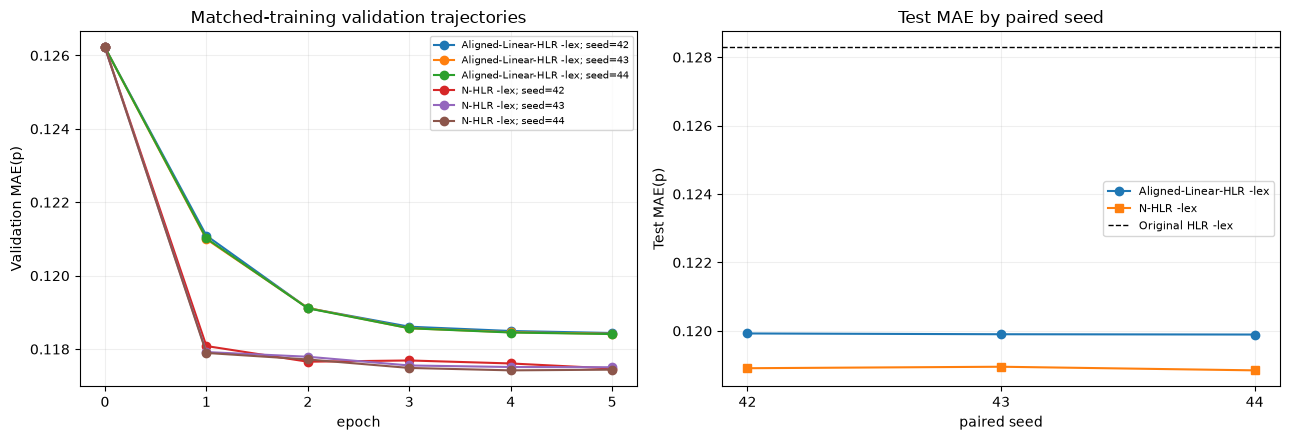

In [5]:
test_seed_results = seed_results[seed_results['split'] == 'Test'].copy()
metric_columns = ['MAE(p)', 'RMSE(p)', 'AUC', 'Spearman(h)', 'mean_prediction', 'share_at_upper_bound']
aggregate = test_seed_results.groupby('model')[metric_columns].agg(['mean', 'std'])
display(aggregate.round(6))

paired = (
    test_seed_results.pivot(index='seed', columns='model', values='MAE(p)')
    .reset_index()
)
paired['MAE gain from nonlinearity'] = (
    paired['Aligned-Linear-HLR -lex'] - paired['N-HLR -lex']
)
display(paired.round(6))
print(
    'Mean paired Test MAE gain (positive favors N-HLR): '
    f"{paired['MAE gain from nonlinearity'].mean():.6f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (model_name, seed), part in trace_results.groupby(['model', 'seed']):
    axes[0].plot(part['epoch'], part['MAE(p)'], marker='o', label=f'{model_name}; seed={seed}')
axes[0].set(
    xlabel='epoch', ylabel='Validation MAE(p)',
    title='Matched-training validation trajectories',
)
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=7)

for model_name, marker in [('Aligned-Linear-HLR -lex', 'o'), ('N-HLR -lex', 's')]:
    part = test_seed_results[test_seed_results['model'] == model_name]
    axes[1].plot(part['seed'], part['MAE(p)'], marker=marker, linewidth=1.5, label=model_name)
axes[1].axhline(
    hlr_reference.loc[hlr_reference['split'] == 'Test', 'MAE(p)'].iloc[0],
    color='black', linestyle='--', linewidth=1, label='Original HLR -lex',
)
axes[1].set(
    xlabel='paired seed', ylabel='Test MAE(p)',
    title='Test MAE by paired seed', xticks=list(SEEDS),
)
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 解释规则与实验限制

- 若 Aligned-Linear 与 N-HLR 的结果接近，而两者都优于原始 HLR，则改善主要来自损失与训练方式。
- 若 Aligned-Linear 接近原始 HLR，而 N-HLR 在三个配对种子下都更好，则结果支持非线性结构带来改善。
- 若 Aligned-Linear 介于两者之间，则训练方式与非线性结构都有贡献。

**实验限制——正则化不可完全等价。** Aligned-Linear 的参数是单个系数向量，而 N-HLR 使用两层参数 $W_1,W_2,b_2$。即使二者采用相同的 `L2=1e-6`，两层网络可以在层间重新缩放参数，因此相同的 L2 系数不代表完全相同的函数级约束。本实验将优化器、损失权重和名义 L2 系数保持一致，但不能把剩余差异严格解释为纯粹的函数非线性。

此外，三个随机种子只能用于检查结果是否在少量重复实验中方向一致，不足以支持正式的统计显著性结论。由于 Test 标签大量位于回忆率上界，解释 MAE 时还应同时查看 RMSE、预测均值和上界预测比例。
